# MuJoCo locomotion: PPO versus SAC

Official HalfCheetah-v5 supplies a 17-dimensional proprioceptive observation and six continuous joint torques. The simulator generates interaction data; no external dataset or pretrained policy is used. PPO and SAC receive the same interaction budget. Their update counts and wall times differ, so this is an interaction-matched comparison, not equal compute.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

torch.set_num_threads(1)


def read(path):
    return json.loads((ROOT / path).read_text())

## Three independent fits

Test summaries average 100 fixed resets per selected policy. Fitting-seed SD measures training variation and differs from a conditional episode bootstrap interval.

In [2]:
rows = []
for path in sorted((ROOT / "results/reference/simulations").glob("HalfCheetah*/*/metrics.json")):
    m = json.loads(path.read_text())
    rows.append(
        dict(
            algorithm=m["algorithm"],
            seed=m["seed"],
            test_return=m["test"]["mean"],
            selected_step=m["selected_step"],
            actual_steps=m["actual_steps"],
        )
    )
frame = pd.DataFrame(rows)
assert len(frame) == 6 and frame.actual_steps.nunique() == 1
frame.groupby("algorithm").test_return.agg(["mean", "std", "min", "max"])

,mean,std,min,max
algorithm,,,,
PPO,1455.730781,89.947286,1354.736246,1527.218336
SAC,8048.699106,386.792969,7605.357311,8317.219134


## Validation-only selection

The checkpoint with highest mean validation return is selected; ties retain the first checkpoint. Test resets never select training settings or a visually appealing episode.

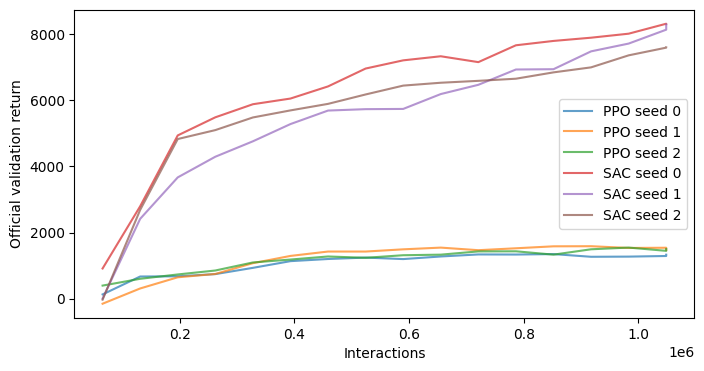

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for row in frame.itertuples():
    h = read(
        f"results/reference/simulations/HalfCheetah-v5_{row.algorithm}_official/{row.seed}/validation_history.json"
    )
    chosen = max(h, key=lambda r: r["mean_return"])
    assert chosen["step"] == row.selected_step
    ax.plot(
        [r["step"] for r in h],
        [r["mean_return"] for r in h],
        label=f"{row.algorithm} seed {row.seed}",
        alpha=0.7,
    )
ax.set(xlabel="Interactions", ylabel="Official validation return")
ax.legend()
plt.show()

## Deploy an exported continuous actor

The actor contains float32 network weights, action bounds and an explicit architecture. Critics, optimizer states and replay buffers are unnecessary for deterministic deployment.

In [4]:
from decision_lab.simulation_deployment import load_actor
from decision_lab.simulations import evaluate

stem = "HalfCheetah-v5_SAC_official_0"
actor = load_actor(ROOT / "assets/actors" / (stem + ".npz"))
fresh = evaluate(actor, actor.metadata["case"], [300000])
evidence = np.load(ROOT / "assets/source_data/simulations" / (stem + ".npz"))
np.testing.assert_array_equal(fresh["returns"], evidence["returns"][:1])
print("Fixed first test return:", fresh["returns"][0], "episode length:", fresh["lengths"][0])
print("Actor dimensions:", actor.metadata["dimensions"])

Fixed first test return: 8228.635301675691 episode length: 1000
Actor dimensions: [17, 256, 256, 6]


## Numerical evidence behind the animation

Both algorithms' GIFs replay fitting seed 0, test reset 300000, including the full episode. A high reward does not certify a human-like gait. Inspect the visual behavior as well as the aggregate return.

In [5]:
for algorithm in ["PPO", "SAC"]:
    gif = read(f"assets/rollouts/HalfCheetah-v5_{algorithm}_official_0.json")
    e = np.load(ROOT / f"assets/source_data/simulations/HalfCheetah-v5_{algorithm}_official_0.npz")
    assert gif["test_seed"] == 300000 and gif["return_value"] == float(e["returns"][0])
    print(algorithm, gif["return_value"], gif["length"], gif["gif_sha256"])

PPO 1431.2379375738492 1000 0fb3009e691905d7262aef0e47d647e6221efa437dad31313f3a1243d6017603
SAC 8228.635301675691 1000 504ab9d0c47fc091a300b80f0d4529945c95a10d3b9b559d29924811dfa6e13d
